# Generating Training Data

In this notebook, the bubble dynamics model is used to generate and store training data.

In [1]:
import sys
sys.path.append("..")
import matplotlib.pyplot as plt
import numpy as np

import wavelet_transform.utils.training_data as train
import wavelet_transform.utils.statistical_features as stats

In [2]:
sampling_rate = 50e6

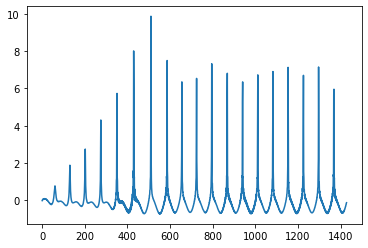

,level,node number,frequency range,centre frequency,energy,log energy,kurtosis,crest factor,skewness,abs skewness,entropy,spectral entropy,level entropy
0,1,0,"(0, 5.0e-1)",0.25,1288.976713,3.110245,17.761522,5.865447,3.669363,3.669363,4.345312,6.877194,4.014728
1,1,1,"(5.0e-1, 1e0)",0.75,139.127000,2.143411,36.279055,10.338675,2.209124,2.209124,3.555326,8.598540,0.573263


,level,node number,frequency range,centre frequency,energy,log energy,kurtosis,crest factor,skewness,abs skewness,entropy,spectral entropy,level entropy
0,0,0,"(0, 1e0)",0.5,1428.0,3.154728,34.181918,9.87352,5.029949,5.029949,4.573395,7.6378,4.573395


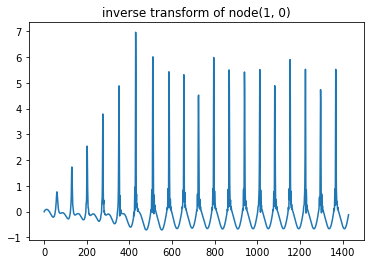

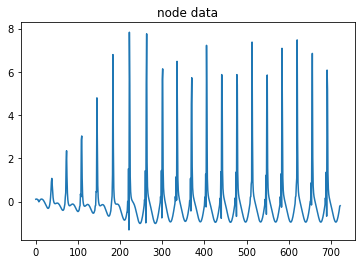

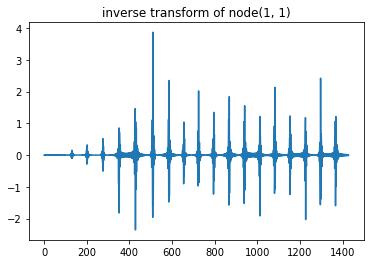

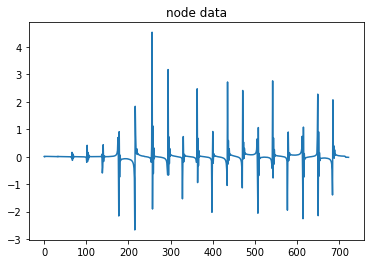

In [3]:
data = train.get_data(R_init=4e-06, frequency=7e5, pac=-7e4, sampling_rate=sampling_rate)
# length = int(2 ** 11)
# data = data[100:]
data = (data - np.mean(data)) / np.std(data)
plt.plot(data)
plt.show()

import wavelet_transform.wpt.transform as wpt
import wavelet_transform.wpt.inverse_transform as inv
tr_obj = wpt.dwpt(data, wavelet="db10", mode="symmetric", min_entropy=True)
display(tr_obj.info(leaf_nodes=True))
display(tr_obj.info(0))

for node in tr_obj.get_leaf_nodes():
    inverse = inv.inv_dwpt(tr_obj, node.level, nodes=node)
    plt.plot(inverse)
    plt.title(f"inverse transform of node{node.level, node.node_number}")
    plt.show()
    plt.plot(node.data)
    plt.title("node data")
    plt.show()

### Model testing

Generating signals using the bubble dynamics model

In [ ]:
R_init = 4e-6
frequency = 3.9e6
pac = -1e5

# Read generated data or generate data and store it
data = train.get_data(R_init, frequency, pac, sampling_rate)  # uses default values for other parameters
if data is None:
    raise ValueError("data could not be generated")

plt.plot(data)
plt.title(f"R_init: {R_init}, frequency: {frequency}, pac: {pac}")
plt.show()

print(stats.kurtosis(data))

### Generating Training Data

Generating training data under a range of intensity (pac), frequency, initial bubble radius (R_init)

In [ ]:
for R_init in (i / 1E6 for i in range(1, 11)):
    for frequency in (i * 1E5 for i in range(7, 10)):
        for pac in (i * -1E4 for i in range(1, 20)):
            print(R_init, frequency, pac)     

            # Read generated data or generate it if it doesn't exist     
            data = train.get_data(R_init, frequency, pac, sampling_rate)
            data = (data - np.mean(data)) / np.std(data)
            if data is None:
                raise ValueError("data could not be generated")

            # c = stats.kurtosis(data)
            # if c > 20:
            # plt.plot(data)
            # plt.title(f"R_init: {R_init}, frequency: {frequency}, pac: {pac}")
            # plt.show()